In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import binomtest, chi2_contingency

sns.set_theme(style="whitegrid")
PROC = Path("../data/processed")
FIG = Path("../figures")

matches = pd.read_csv(PROC / "matches.csv", dtype={"match_id": str}, parse_dates=["date"])
dec = matches[matches["result"] == "win"].copy()
dec["toss_winner_won"] = dec["toss_winner"] == dec["winner"]
dec["year"] = dec["date"].dt.year
print(f"Decisive matches: {len(dec)}")

Decisive matches: 2447


In [2]:
def toss_test(s):
    k, n = int(s.sum()), len(s)
    r = binomtest(k, n, p=0.5)
    ci = r.proportion_ci(confidence_level=0.95)
    return pd.Series({"wins": k, "n": n, "rate": k / n,
                      "ci_low": ci.low, "ci_high": ci.high, "p_value": r.pvalue})

overall = toss_test(dec["toss_winner_won"])
print(overall.round(4))

wins       1222.0000
n          2447.0000
rate          0.4994
ci_low        0.4794
ci_high       0.5194
p_value       0.9678
dtype: float64


#### Does the toss decision matter?

In [3]:
by_decision = dec.groupby("toss_decision")["toss_winner_won"].apply(toss_test).unstack()
print(by_decision.round(4))

# Is the difference between bat and field itself significant?
table = pd.crosstab(dec["toss_decision"], dec["toss_winner_won"])
chi2, p, _, _ = chi2_contingency(table)
print(f"\nBat vs field difference: chi-square = {chi2:.2f}, p = {p:.4f}")

                wins       n    rate  ci_low  ci_high  p_value
toss_decision                                                 
bat            570.0  1196.0  0.4766  0.4480   0.5053   0.1117
field          652.0  1251.0  0.5212  0.4931   0.5492   0.1415

Bat vs field difference: chi-square = 4.69, p = 0.0304


#### Has the effect changed over time?

In [4]:
dec["era"] = pd.cut(dec["year"], bins=[2001, 2009, 2017, 2026],
                    labels=["2002–2009", "2010–2017", "2018–2026"])
by_era = dec.groupby("era", observed=True)["toss_winner_won"].apply(toss_test).unstack()
print(by_era.round(4))

n_tests = 1 + len(by_decision) + len(by_era)
print(f"\nTests run: {n_tests}. Bonferroni threshold: p < {0.05 / n_tests:.4f}")

            wins      n    rate  ci_low  ci_high  p_value
era                                                      
2002–2009  358.0  710.0  0.5042  0.4668   0.5416   0.8512
2010–2017  400.0  828.0  0.4831  0.4486   0.5177   0.3481
2018–2026  464.0  909.0  0.5105  0.4774   0.5434   0.5505

Tests run: 6. Bonferroni threshold: p < 0.0083


#### How has toss strategy changed?

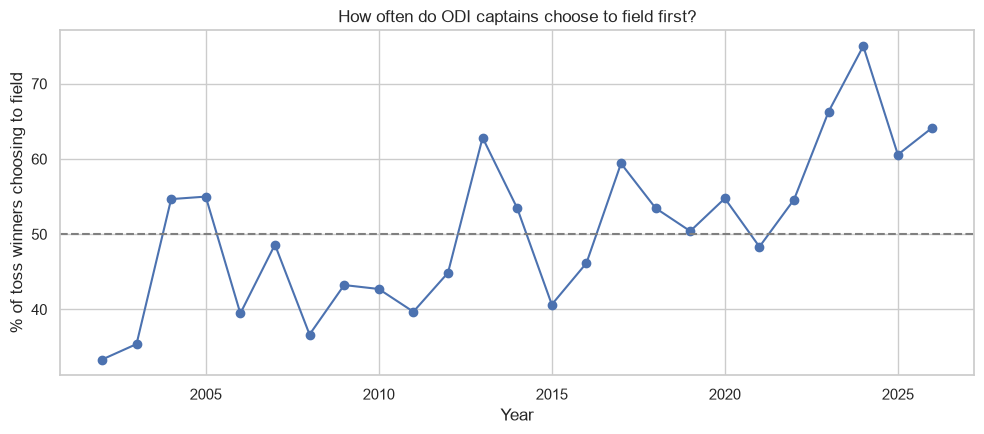

In [7]:
field_share = dec.groupby("year")["toss_decision"].apply(lambda s: (s == "field").mean())

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(field_share.index, field_share * 100, marker="o")
ax.axhline(50, ls="--", color="grey")
ax.set(xlabel="Year", ylabel="% of toss winners choosing to field",
       title="How often do ODI captains choose to field first?")
plt.tight_layout()
plt.savefig(FIG / "toss_decision_trend.png", dpi=150)
plt.show()

## The Summary Chart

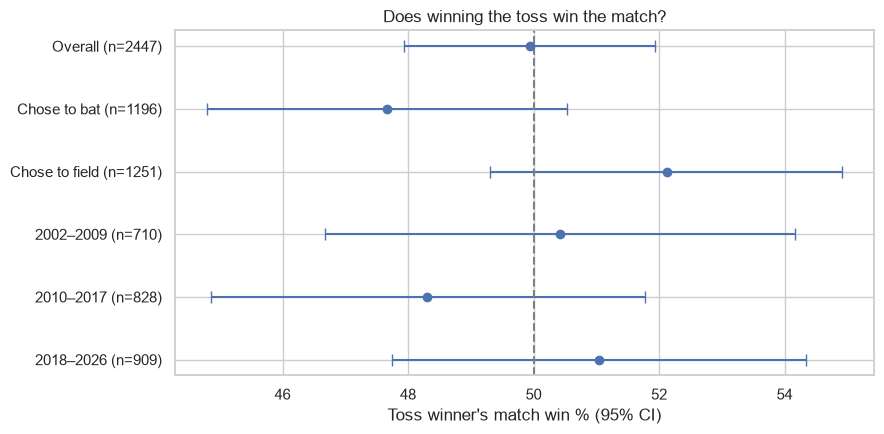

In [8]:
summary = pd.concat([
    overall.to_frame("Overall").T,
    by_decision.rename(index=lambda x: f"Chose to {x}"),
    by_era,
])

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(summary))
err = [(summary["rate"] - summary["ci_low"]) * 100, (summary["ci_high"] - summary["rate"]) * 100]
ax.errorbar(summary["rate"] * 100, y, xerr=err, fmt="o", capsize=4)
ax.axvline(50, ls="--", color="grey")
ax.set_yticks(y)
ax.set_yticklabels([f"{i} (n={int(n)})" for i, n in zip(summary.index, summary["n"])])
ax.invert_yaxis()
ax.set(xlabel="Toss winner's match win % (95% CI)", title="Does winning the toss win the match?")
plt.tight_layout()
plt.savefig(FIG / "toss_effect.png", dpi=150)
plt.show()